In [176]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

tabela = pd.read_excel("atividade_transformacao_logaritmica.xlsx")
tabela

,ID_Loja,Regiao,Canal_Principal,Meses_Plataforma,Visitas_Mensais,Investimento_Mkt_BRL,Receita_Mensal_BRL
0,LJ-001,Centro-Oeste,E-mail Marketing,28,1990,16326.13,180845.14
1,LJ-002,Sul,Indicação,30,3886,472.55,116643.32
2,LJ-003,Sudeste,Mídia Paga,29,2695,1198.79,111351.05
3,LJ-004,Sudeste,Orgânico,6,4391,1565.70,60254.06
4,LJ-005,Nordeste,Orgânico,35,408,15570.81,77586.62
...,...,...,...,...,...,...,...
115,LJ-116,Sul,E-mail Marketing,1,705,0.00,15562.40
116,LJ-117,Sul,Orgânico,5,535,1126.86,26443.72
117,LJ-118,Nordeste,Orgânico,4,288,656.82,26518.49
118,LJ-119,Sul,Mídia Paga,16,923,222.66,61698.68


In [177]:
visitas_regiao = tabela.groupby("Regiao")["Visitas_Mensais"].sum().reset_index(name= "Visitas_Mensais")
visitas_regiao

,Regiao,Visitas_Mensais
0,Centro-Oeste,32911
1,Nordeste,452527
2,Norte,545961
3,Sudeste,89496
4,Sul,321686


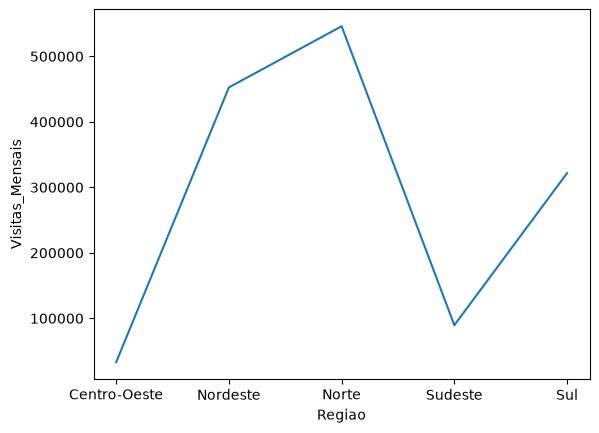

In [178]:
sns.lineplot(
    data = visitas_regiao,
    x = "Regiao",
    y = "Visitas_Mensais"
)

plt.show()

In [179]:
visitas_regiao["Visitas_Mensais"] = np.log1p(visitas_regiao["Visitas_Mensais"])

visitas_regiao

,Regiao,Visitas_Mensais
0,Centro-Oeste,10.401593
1,Nordeste,13.022605
2,Norte,13.210305
3,Sudeste,11.401960
4,Sul,12.681334


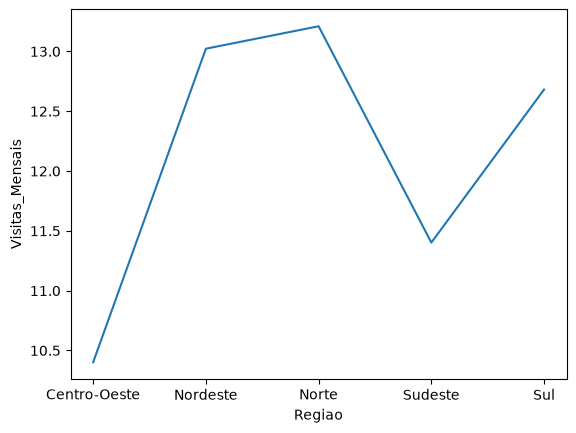

In [180]:
sns.lineplot(
    data = visitas_regiao,
    x = "Regiao",
    y = "Visitas_Mensais"
)

plt.show()

In [181]:
nordeste = tabela[tabela["Regiao"] == "Nordeste"]

nordeste

,ID_Loja,Regiao,Canal_Principal,Meses_Plataforma,Visitas_Mensais,Investimento_Mkt_BRL,Receita_Mensal_BRL
4,LJ-005,Nordeste,Orgânico,35,408,15570.81,77586.62
5,LJ-006,Nordeste,Mídia Paga,24,390000,42000.00,485000.00
13,LJ-014,Nordeste,Mídia Paga,33,599,11846.67,104536.24
14,LJ-015,Nordeste,Indicação,3,828,3243.91,66409.45
15,LJ-016,Nordeste,Mídia Paga,18,1178,0.00,24221.37
16,LJ-017,Nordeste,Mídia Paga,25,227,3104.32,31703.34
19,LJ-020,Nordeste,Indicação,24,8149,3126.78,186183.98
21,LJ-022,Nordeste,Orgânico,22,5850,5933.15,158227.02
22,LJ-023,Nordeste,Mídia Paga,23,1296,0.00,23471.37
26,LJ-027,Nordeste,Mídia Paga,26,2244,1185.38,175274.04


In [182]:
nordeste = nordeste.sort_values("Visitas_Mensais")
nordeste


,ID_Loja,Regiao,Canal_Principal,Meses_Plataforma,Visitas_Mensais,Investimento_Mkt_BRL,Receita_Mensal_BRL
44,LJ-045,Nordeste,Orgânico,23,150,3051.61,22678.87
16,LJ-017,Nordeste,Mídia Paga,25,227,3104.32,31703.34
71,LJ-072,Nordeste,Indicação,28,249,4523.93,32861.29
64,LJ-065,Nordeste,Orgânico,35,256,329.89,21960.77
117,LJ-118,Nordeste,Orgânico,4,288,656.82,26518.49
90,LJ-091,Nordeste,Mídia Paga,16,376,2792.68,33382.34
4,LJ-005,Nordeste,Orgânico,35,408,15570.81,77586.62
105,LJ-106,Nordeste,Orgânico,30,440,4097.53,41205.69
79,LJ-080,Nordeste,E-mail Marketing,34,487,1364.31,137932.00
40,LJ-041,Nordeste,Mídia Paga,8,497,138.43,17334.52


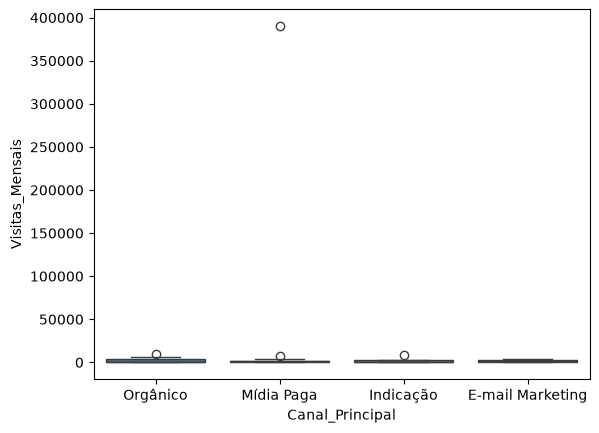

In [183]:
sns.boxplot(
    data = nordeste,
    y = "Visitas_Mensais",
    x = "Canal_Principal",
    hue = "Canal_Principal"
)
plt.show()

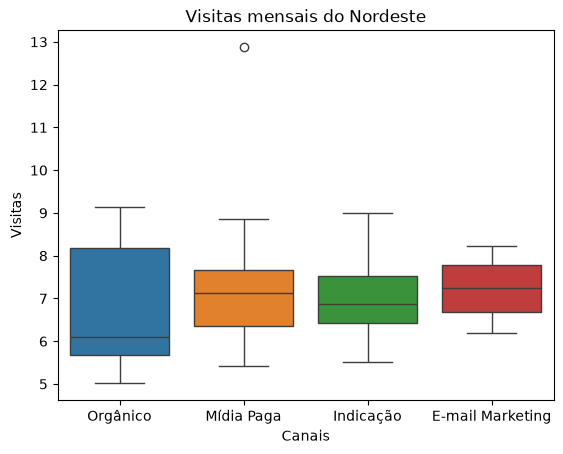

In [184]:
nordeste["Visitas_Mensais"] = np.log1p(nordeste["Visitas_Mensais"])
plt.title("Visitas mensais do Nordeste")
sns.boxplot(
    data = nordeste,
    y = "Visitas_Mensais",
    x = "Canal_Principal",
    hue = "Canal_Principal"
)
plt.ylabel("Visitas")
plt.xlabel("Canais")
plt.show()

In [185]:
nordeste["Receita_Mensal_BRL"] = np.log1p(nordeste["Receita_Mensal_BRL"])

dispersao_email = nordeste[nordeste["Canal_Principal"] == "E-mail Marketing"]

dispersao_email

,ID_Loja,Regiao,Canal_Principal,Meses_Plataforma,Visitas_Mensais,Investimento_Mkt_BRL,Receita_Mensal_BRL
79,LJ-080,Nordeste,E-mail Marketing,34,6.190315,1364.31,11.834523
110,LJ-111,Nordeste,E-mail Marketing,34,6.846943,1045.03,11.410600
99,LJ-100,Nordeste,E-mail Marketing,16,7.648263,0.00,10.348878
66,LJ-067,Nordeste,E-mail Marketing,13,8.219326,0.00,10.145789


<Axes: xlabel='Visitas_Mensais', ylabel='Receita_Mensal_BRL'>

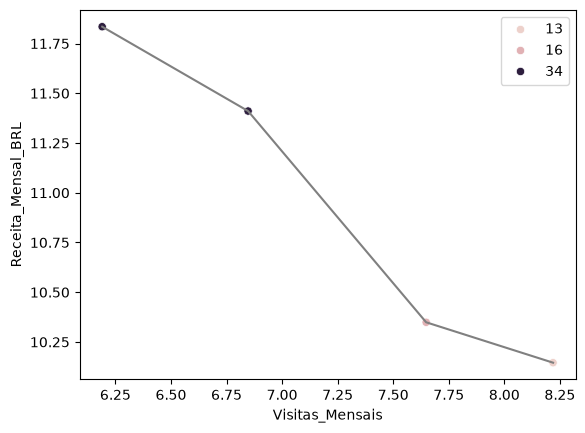

In [186]:
sns.scatterplot(
    data = dispersao_email,
    x = "Visitas_Mensais",
    y = "Receita_Mensal_BRL",
    hue = "Meses_Plataforma"
)

sns.lineplot(
    data = dispersao_email,
    x = "Visitas_Mensais",
    y = "Receita_Mensal_BRL",
    color = "gray"
)

In [187]:
prejuizo = tabela[["Canal_Principal", "Visitas_Mensais", "Receita_Mensal_BRL"]]

prejuizo


,Canal_Principal,Visitas_Mensais,Receita_Mensal_BRL
0,E-mail Marketing,1990,180845.14
1,Indicação,3886,116643.32
2,Mídia Paga,2695,111351.05
3,Orgânico,4391,60254.06
4,Orgânico,408,77586.62
...,...,...,...
115,E-mail Marketing,705,15562.40
116,Orgânico,535,26443.72
117,Orgânico,288,26518.49
118,Mídia Paga,923,61698.68


In [188]:
prejuizo["Visitas_Mensais"] = np.log1p(prejuizo["Visitas_Mensais"])

prejuizo["Receita_Mensal_BRL"] = np.log1p(prejuizo["Receita_Mensal_BRL"])

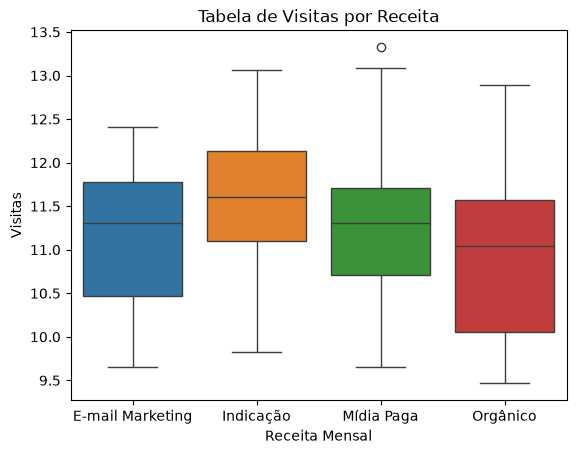

In [189]:
plt.title("Tabela de Visitas por Receita")
sns.boxplot(
    data = prejuizo,
    x = "Canal_Principal",
    y = "Receita_Mensal_BRL",
    hue = "Canal_Principal"
)
plt.ylabel("Visitas")
plt.xlabel("Receita Mensal")
plt.show()

In [190]:
canais = tabela[["Canal_Principal", "Investimento_Mkt_BRL"]]
canais = canais.groupby("Canal_Principal")["Investimento_Mkt_BRL"].mean().reset_index(name = "Investimento_Mkt_BRL")

In [191]:
prejuizo_invest = canais.sort_values(by = "Investimento_Mkt_BRL", ascending = False).reset_index(drop=True)
prejuizo_invest["Acumulado"] = prejuizo_invest["Investimento_Mkt_BRL"].cumsum()
prejuizo_invest["Percentual Acumulado"] = (prejuizo_invest["Acumulado"]/prejuizo_invest["Investimento_Mkt_BRL"].sum())*100

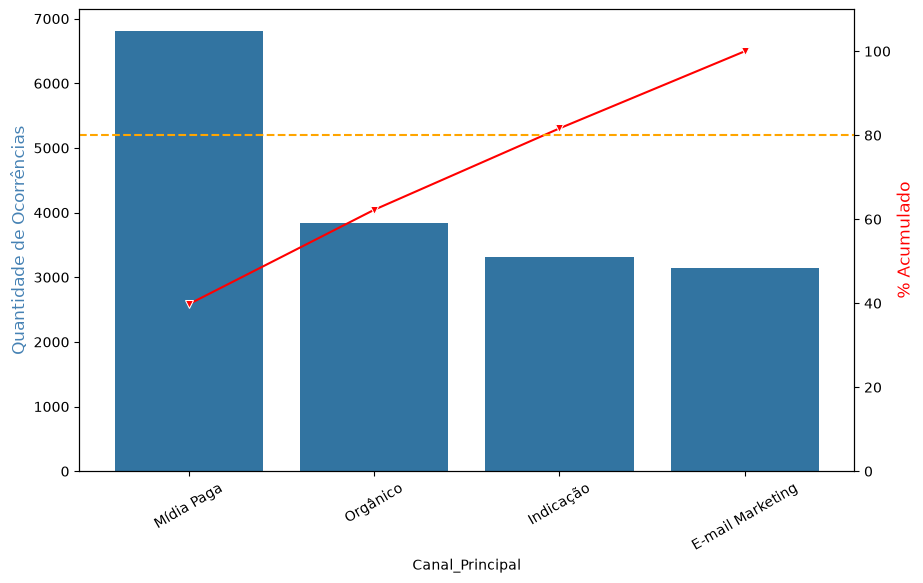

In [192]:
fig, ax1 = plt.subplots(figsize=(10,6))

sns.barplot(
    data = prejuizo_invest,
    x = "Canal_Principal",
    y = "Investimento_Mkt_BRL",
    ax = ax1
)

ax1.set_ylabel("Quantidade de Ocorrências", color = "steelblue", fontsize = 12)
ax1.tick_params(axis = "x", rotation = 30)

ax2  = ax1.twinx()

sns.lineplot(
    data = prejuizo_invest,
    x = prejuizo_invest.index,
    y = "Percentual Acumulado",
    color = "red",
    marker = "v",
    ax = ax2
)

ax2.set_ylim(0,110)
ax2.set_ylabel("% Acumulado", color = "red", fontsize = 12)
ax2.axhline(80, color = "orange", linestyle = "--", label = "Corte 80%")